# BatteryIQ — ML Baseline & Model Validation

## Objective

Develop and evaluate baseline machine-learning models for predicting
battery State of Health (SOH) from cycle-level battery characteristics.

### Pipeline

Features
↓
Target Construction
↓
Battery-Level Train/Test Strategy
↓
Model Training
↓
Evaluation
↓
Model Comparison

### Candidate Models

1. Linear Regression
2. Random Forest
3. SVR
4. XGBoost

### Primary Metrics

- MAE
- RMSE
- R²

### Validation Strategy

Leave-One-Battery-Out validation is used to evaluate
generalization to unseen batteries.

In [13]:
import numpy as np
import pandas as pd

from pathlib import Path

print("ML environment ready!")

ML environment ready!


In [14]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

FEATURE_FILE = (
    PROJECT_ROOT
    / "data"
    / "features"
    / "battery_cycle_features.csv"
)

TARGET_FILE = (
    PROJECT_ROOT
    / "data"
    / "features"
    / "battery_cycle_targets.csv"
)

print("Feature file:", FEATURE_FILE)
print("Target file:", TARGET_FILE)

print("\nFeature file exists:", FEATURE_FILE.exists())
print("Target file exists:", TARGET_FILE.exists())

Feature file: d:\VIT Academic\TY\sem 5\EDI\BatteryIQ\data\features\battery_cycle_features.csv
Target file: d:\VIT Academic\TY\sem 5\EDI\BatteryIQ\data\features\battery_cycle_targets.csv

Feature file exists: True
Target file exists: True


In [15]:
features_df = pd.read_csv(FEATURE_FILE)
targets_df = pd.read_csv(TARGET_FILE)

print("Features shape:", features_df.shape)
print("Targets shape:", targets_df.shape)

Features shape: (636, 17)
Targets shape: (636, 4)


In [16]:
ml_df = pd.merge(
    features_df,
    targets_df,
    on=["battery_id", "cycle"],
    how="inner",
    validate="one_to_one"
)

print("ML dataset shape:", ml_df.shape)
display(ml_df.head())

ML dataset shape: (636, 19)


,battery_id,cycle,voltage_mean,voltage_min,voltage_max,voltage_std,current_mean,current_min,current_max,temperature_mean,temperature_max,current_load_mean,voltage_load_mean,cycle_time,voltage_change,temperature_change,temperature_rolling_mean,capacity,soh
0,B0005,1,3.529829,2.612467,4.191492,0.236558,-1.818702,-2.018015,0.000729,32.572328,38.982181,-1.805570,2.404944,3690.234,0.000000,0.000000,32.572328,1.856487,92.824371
1,B0005,2,3.537320,2.587209,4.189773,0.235366,-1.817560,-2.016821,0.002927,32.725235,39.033398,-1.804583,2.399260,3672.344,0.007491,0.152907,32.648782,1.846327,92.316362
2,B0005,3,3.543737,2.651917,4.188187,0.228111,-1.816487,-2.016574,0.001484,32.642862,38.818797,-1.803575,2.397969,3651.641,0.006417,-0.082373,32.646808,1.835349,91.767460
3,B0005,4,3.543666,2.592948,4.188461,0.233347,-1.825589,-2.015936,0.001547,32.514876,38.762305,-1.812863,2.408289,3631.563,-0.000071,-0.127985,32.613825,1.835263,91.763126
4,B0005,5,3.542343,2.547420,4.188299,0.237301,-1.826114,-2.017426,0.001701,32.382349,38.665393,-1.812876,2.408505,3629.172,-0.001323,-0.132527,32.567530,1.834646,91.732275


In [17]:
print("Missing values:", ml_df.isna().sum().sum())
print("Duplicate rows:", ml_df.duplicated().sum())

print("\nBatteries:")
print(sorted(ml_df["battery_id"].unique()))

print("\nCycles:")
print(
    ml_df.groupby("battery_id")["cycle"].nunique()
)

Missing values: 0
Duplicate rows: 0

Batteries:
['B0005', 'B0006', 'B0007', 'B0018']

Cycles:
battery_id
B0005    168
B0006    168
B0007    168
B0018    132
Name: cycle, dtype: int64


In [18]:
TARGET = "soh"

GROUP_COLUMN = "battery_id"

DROP_COLUMNS = [
    "battery_id",
    "soh",
    "capacity"
]

X = ml_df.drop(columns=DROP_COLUMNS)
y = ml_df[TARGET]

groups = ml_df[GROUP_COLUMN]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures used:")
print(X.columns.tolist())

X shape: (636, 16)
y shape: (636,)

Features used:
['cycle', 'voltage_mean', 'voltage_min', 'voltage_max', 'voltage_std', 'current_mean', 'current_min', 'current_max', 'temperature_mean', 'temperature_max', 'current_load_mean', 'voltage_load_mean', 'cycle_time', 'voltage_change', 'temperature_change', 'temperature_rolling_mean']


In [19]:
from sklearn.model_selection import LeaveOneGroupOut

logo = LeaveOneGroupOut()

print("Number of validation folds:", logo.get_n_splits(X, y, groups))

Number of validation folds: 4


## Model Development

The models are evaluated using Leave-One-Battery-Out validation.

For each fold, one complete battery is held out for testing while the
remaining batteries are used for training.

Feature scaling is applied only to models that require it and is fitted
within the training portion of each fold to prevent data leakage.

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.base import clone

print("ML libraries imported successfully!")

ML libraries imported successfully!


In [21]:
try:
    from xgboost import XGBRegressor
    print("XGBoost available!")
except ImportError:
    print("XGBoost is not installed.")

XGBoost available!


In [22]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "SVR": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVR(
            kernel="rbf",
            C=10,
            epsilon=0.1
        ))
    ]),

    "XGBoost": XGBRegressor(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
}

print("Models configured:")
for name in models:
    print("-", name)

Models configured:
- Linear Regression
- Random Forest
- SVR
- XGBoost


## Leave-One-Battery-Out Model Evaluation

Each model is evaluated four times.

In every fold:

- One battery is completely held out.
- The remaining batteries form the training set.
- Any preprocessing is fitted only on the training batteries.
- Predictions are generated for the unseen battery.
- MAE, RMSE, and R² are calculated.

This evaluates how well the model generalizes to a battery not observed during training.

In [23]:
def evaluate_model(model, X, y, groups):

    fold_results = []
    all_predictions = []

    for train_idx, test_idx in logo.split(X, y, groups):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        test_battery = groups.iloc[test_idx].iloc[0]

        model_fold = clone(model)

        # Fit only on training batteries
        model_fold.fit(X_train, y_train)

        # Predict unseen battery
        y_pred = model_fold.predict(X_test)

        mae = mean_absolute_error(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        r2 = r2_score(y_test, y_pred)

        fold_results.append({
            "test_battery": test_battery,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        fold_predictions = pd.DataFrame({
            "battery_id": test_battery,
            "cycle": ml_df.iloc[test_idx]["cycle"].values,
            "actual_soh": y_test.values,
            "predicted_soh": y_pred
        })

        all_predictions.append(fold_predictions)

    fold_results_df = pd.DataFrame(fold_results)
    predictions_df = pd.concat(
        all_predictions,
        ignore_index=True
    )

    return fold_results_df, predictions_df

In [24]:
comparison_rows = []

for name, results in model_results.items():

    comparison_rows.append({
        "Model": name,
        "MAE": results["MAE"].mean(),
        "RMSE": results["RMSE"].mean(),
        "R2": results["R2"].mean()
    })

comparison_df = pd.DataFrame(comparison_rows)

comparison_df = comparison_df.sort_values(
    by="RMSE"
).reset_index(drop=True)

display(comparison_df)

NameError: name 'model_results' is not defined

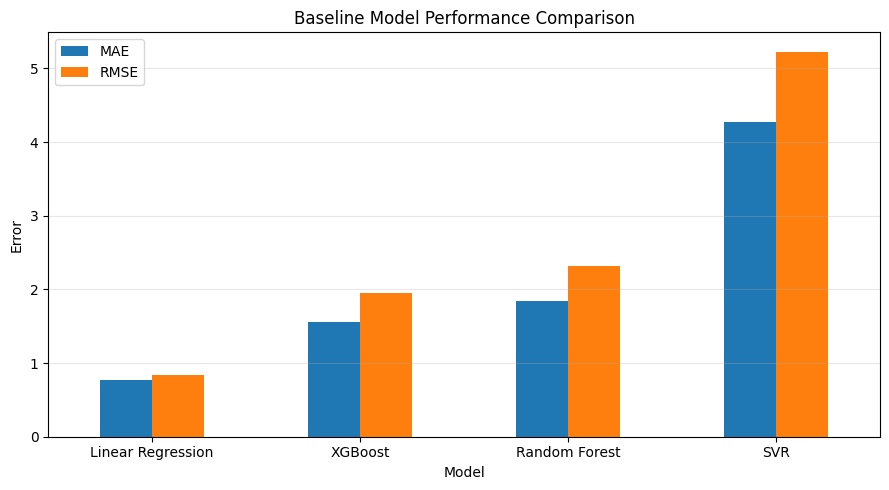

In [ ]:
# Model performance comparison

comparison_plot = comparison_df.set_index("Model")[["MAE", "RMSE"]]

comparison_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Baseline Model Performance Comparison")
plt.ylabel("Error")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

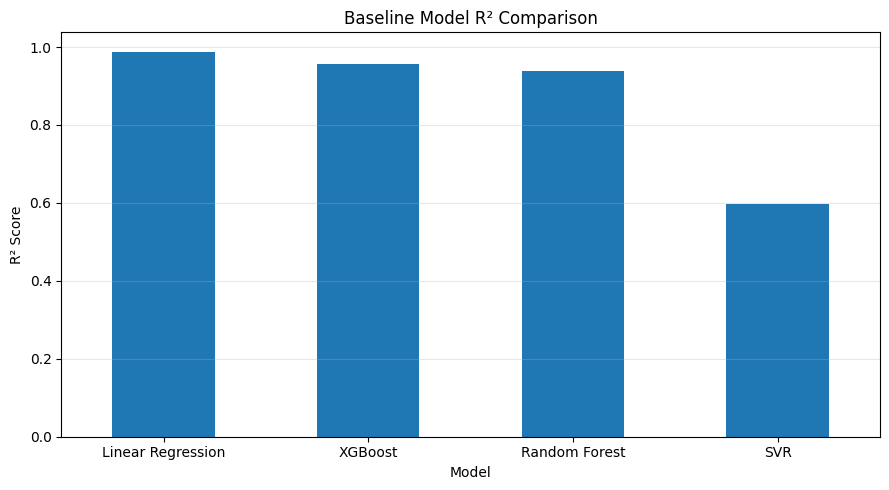

In [ ]:
# R² comparison

comparison_df.set_index("Model")["R2"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Baseline Model R² Comparison")
plt.ylabel("R² Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
best_model_name = comparison_df.iloc[0]["Model"]

print("Best baseline model based on RMSE:")
print(best_model_name)

Best baseline model based on RMSE:
Linear Regression


In [ ]:
for name, results in model_results.items():

    print(f"\n{'=' * 60}")
    print(name)
    print("=" * 60)

    display(results)


Linear Regression


,test_battery,MAE,RMSE,R2
0,B0005,1.367515,1.397842,0.978314
1,B0006,0.259366,0.367719,0.999143
2,B0007,1.079370,1.145041,0.979634
3,B0018,0.378206,0.464773,0.996371



Random Forest


,test_battery,MAE,RMSE,R2
0,B0005,2.173109,2.597628,0.925112
1,B0006,2.284466,3.250103,0.933086
2,B0007,0.911013,1.170776,0.978708
3,B0018,1.982213,2.260443,0.914151



SVR


,test_battery,MAE,RMSE,R2
0,B0005,1.973296,2.460073,0.932833
1,B0006,4.285225,5.900898,0.779425
2,B0007,6.678306,7.787755,0.057907
3,B0018,4.133341,4.761149,0.619136



XGBoost


,test_battery,MAE,RMSE,R2
0,B0005,1.325914,1.567538,0.972729
1,B0006,2.388701,3.186130,0.935695
2,B0007,0.720047,0.983070,0.984988
3,B0018,1.778210,2.066662,0.928240


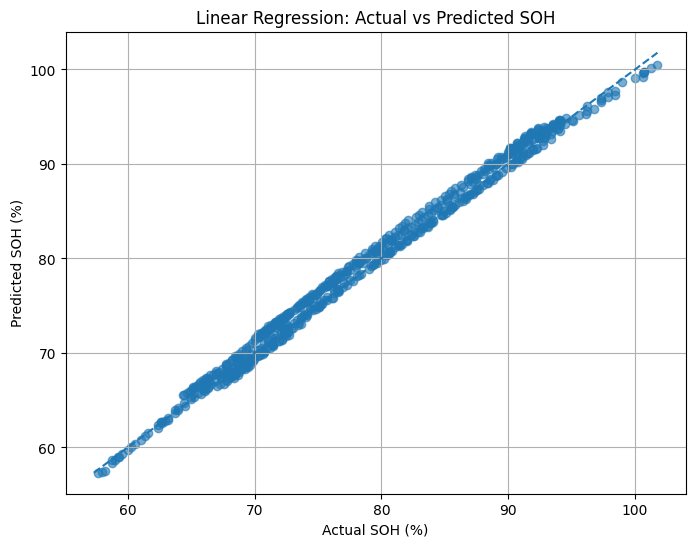

In [ ]:
import matplotlib.pyplot as plt

best_predictions = model_predictions[best_model_name]

plt.figure(figsize=(8, 6))

plt.scatter(
    best_predictions["actual_soh"],
    best_predictions["predicted_soh"],
    alpha=0.6
)

min_soh = min(
    best_predictions["actual_soh"].min(),
    best_predictions["predicted_soh"].min()
)

max_soh = max(
    best_predictions["actual_soh"].max(),
    best_predictions["predicted_soh"].max()
)

plt.plot(
    [min_soh, max_soh],
    [min_soh, max_soh],
    linestyle="--"
)

plt.xlabel("Actual SOH (%)")
plt.ylabel("Predicted SOH (%)")
plt.title(f"{best_model_name}: Actual vs Predicted SOH")
plt.grid(True)

plt.show()

In [ ]:
best_predictions["error"] = (
    best_predictions["predicted_soh"]
    - best_predictions["actual_soh"]
)

best_predictions["absolute_error"] = (
    best_predictions["error"].abs()
)

display(
    best_predictions[
        [
            "battery_id",
            "cycle",
            "actual_soh",
            "predicted_soh",
            "error",
            "absolute_error"
        ]
    ].head(10)
)
print("Mean absolute error:")
print(best_predictions["absolute_error"].mean())

print("\nMaximum absolute error:")
print(best_predictions["absolute_error"].max())

,battery_id,cycle,actual_soh,predicted_soh,error,absolute_error
0,B0005,1,92.824371,93.908752,1.084381,1.084381
1,B0005,2,92.316362,93.657160,1.340798,1.340798
2,B0005,3,91.767460,93.407562,1.640102,1.640102
3,B0005,4,91.763126,93.255897,1.492771,1.492771
4,B0005,5,91.732275,93.142061,1.409785,1.409785
5,B0005,6,91.783083,93.204522,1.421439,1.421439
6,B0005,7,91.757307,93.153139,1.395832,1.395832
7,B0005,8,91.287840,92.988994,1.701154,1.701154
8,B0005,9,91.238693,92.696402,1.457709,1.457709
9,B0005,10,91.230663,92.537661,1.306998,1.306998


Mean absolute error:
0.7933544415014344

Maximum absolute error:
1.935127500521233


In [ ]:
battery_error = (
    best_predictions
    .groupby("battery_id")["absolute_error"]
    .agg(
        mean_absolute_error="mean",
        maximum_absolute_error="max"
    )
    .reset_index()
)

display(battery_error)

,battery_id,mean_absolute_error,maximum_absolute_error
0,B0005,1.367515,1.935128
1,B0006,0.259366,1.448382
2,B0007,1.079370,1.795341
3,B0018,0.378206,1.038491


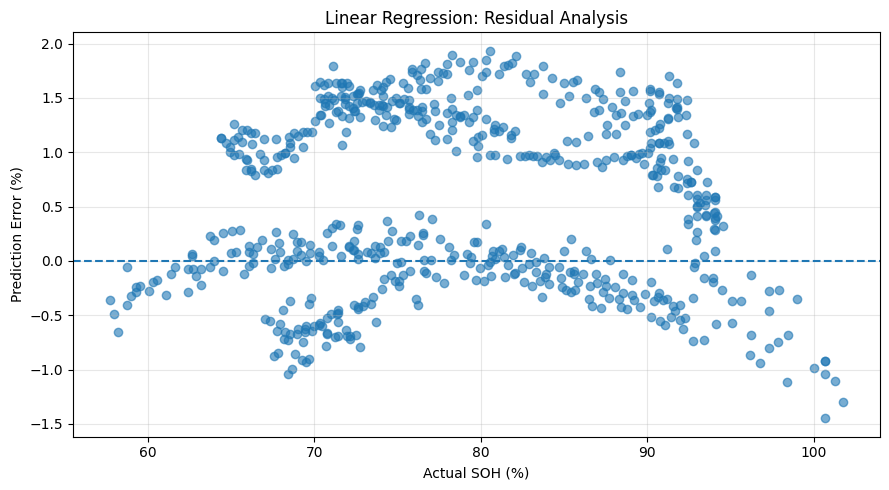

In [ ]:
# Residual analysis

plt.figure(figsize=(9, 5))

plt.scatter(
    best_predictions["actual_soh"],
    best_predictions["error"],
    alpha=0.6
)

plt.axhline(0, linestyle="--")

plt.xlabel("Actual SOH (%)")
plt.ylabel("Prediction Error (%)")
plt.title(f"{best_model_name}: Residual Analysis")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Key ML Findings

- Linear Regression achieved the best overall baseline performance under Leave-One-Battery-Out validation.
- The model achieved an average MAE of approximately 0.77 percentage points and RMSE of approximately 0.84 percentage points.
- The high average R² of approximately 0.988 indicates that the selected cycle-level features explain most of the observed SOH variation.
- XGBoost and Random Forest provided weaker baseline performance than Linear Regression on the current dataset.
- SVR showed substantially higher prediction error and lower R², indicating weaker generalization across unseen batteries.
- Battery-wise errors varied, showing that model performance depends on battery-specific degradation behavior.
- The results provide a strong baseline for future hyperparameter tuning, feature selection, and more advanced models.

## Validation Strategy

Leave-One-Battery-Out validation was used to evaluate generalization to unseen batteries.

For each fold:

- One complete battery was held out for testing.
- The remaining batteries were used for training.
- Model preprocessing was fitted only on the training data.
- Predictions were generated for the unseen battery.
- MAE, RMSE and R² were calculated for each held-out battery.

This validation strategy is more appropriate than a random train-test split for this dataset because measurements from the same battery are strongly correlated across cycles. Holding out an entire battery provides a more realistic estimate of performance on a previously unseen battery.

# Final Baseline Conclusion

The baseline ML pipeline successfully predicts battery State of Health (SOH) from cycle-level battery operating characteristics.

Among the evaluated models, Linear Regression achieved the strongest performance under Leave-One-Battery-Out validation, mean fold-level MAE of approximately 0.77 percentage points and RMSE of approximately 0.84 percentage points and R² of approximately 0.988.

The results demonstrate that the engineered voltage, current, temperature and discharge-duration features contain substantial information about battery degradation.

The baseline establishes a reference point for subsequent model improvement, feature selection, hyperparameter optimization and advanced battery health prediction methods.